# YOLOv8n-seg: segmentación de peces (clase única) con datasets combinados

Entrena un `yolov8n-seg` para segmentar **cualquier pez**, sin distinguir especie. Usa dos fuentes:

- `dataset/` — peces del Paraná (benchmark), ya con split train/val/test agrupado por `group`.
- `datasets_roboflow/fish_sam2_masks_split/` — máscaras generadas con SAM2 (21 especies de mercado), también con split propio.

Se respeta el split original de cada fuente (no se re-mezcla, para no introducir fugas entre fotos casi duplicadas) y se unen por split.
Todas las etiquetas pasan a la clase `0 = pez`. Las métricas se reportan sobre el val/test combinado y **por fuente**.
Hiperparámetros iguales a `fish_seg_benchmark.ipynb` (GTX 1650 4 GB).

In [1]:
import json, os, shutil, time
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ultralytics import YOLO

ROOT = Path.cwd()
SOURCES = {
    "parana":   ROOT / "dataset",
    "roboflow": ROOT / "datasets_roboflow" / "fish_sam2_masks_split",
}
OUT  = (ROOT / "dataset_merged").resolve()   # dataset combinado generado
RUNS = (ROOT / "runs").resolve()
RUN_NAME = "yolov8n-seg_merged"
SEED = 42
CLASS_NAME = "pez"
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
RUNS.mkdir(exist_ok=True)

## 1. Combinar datasets (clase única)

Cada imagen se enlaza (hardlink; si falla, se copia) con prefijo de fuente para evitar colisiones de nombres. Los labels se reescriben con clase `0`.

In [2]:
def link_or_copy(src, dst):
    try:
        os.link(src, dst)
    except OSError:
        shutil.copy2(src, dst)

# Se regenera desde cero para no arrastrar archivos de corridas previas
shutil.rmtree(OUT, ignore_errors=True)
rows = []
for src_name, src in SOURCES.items():
    for split in ["train", "val", "test"]:
        (OUT / "images" / split).mkdir(parents=True, exist_ok=True)
        (OUT / "labels" / split).mkdir(parents=True, exist_ok=True)
        for img in sorted((src / "images" / split).iterdir()):
            if img.suffix.lower() not in IMG_EXT:
                continue
            lbl = src / "labels" / split / (img.stem + ".txt")
            if not lbl.exists():
                continue
            lines = [l.split() for l in lbl.read_text().splitlines() if l.strip()]
            lines = [["0"] + l[1:] for l in lines if len(l) >= 7]      # todo es "pez"; descarta polígonos degenerados
            if not lines:
                continue
            name = f"{src_name}__{img.name}"
            link_or_copy(img, OUT / "images" / split / name)
            (OUT / "labels" / split / (Path(name).stem + ".txt")).write_text("\n".join(" ".join(l) for l in lines))
            rows.append(dict(source=src_name, split=split, name=name, n_inst=len(lines)))

df = pd.DataFrame(rows)
df.to_csv(OUT / "index.csv", index=False)

# listas por fuente para validar/testear cada una por separado
for (s, sp), g in df.groupby(["source", "split"]):
    (OUT / f"{sp}_{s}.txt").write_text("\n".join(str(OUT / "images" / sp / n) for n in g.name))

def write_yaml(fname, **splits):
    body = "".join(f"{k}: {v}\n" for k, v in splits.items())
    (OUT / fname).write_text(f"path: {OUT.as_posix()}\n{body}names:\n  0: {CLASS_NAME}\n")

write_yaml("data.yaml", train="images/train", val="images/val", test="images/test")
for s in SOURCES:
    write_yaml(f"data_{s}.yaml", train="images/train", val=f"val_{s}.txt", test=f"test_{s}.txt")

print(pd.crosstab(df.source, df.split, margins=True)[["train", "val", "test", "All"]])
print("\nInstancias por imagen (media):", df.groupby("source").n_inst.mean().round(2).to_dict())

import gc
# 1. Guardar el CSV con los datos de train/val/test
df.to_csv(OUT / "index.csv", index=False)
# 2. Eliminar las variables pesadas de la memoria RAM
del df, rows
gc.collect()

split     train  val  test   All
source                          
parana      913  194   209  1316
roboflow   3293  718   718  4729
All        4206  912   927  6045

Instancias por imagen (media): {'parana': 1.0, 'roboflow': 1.0}


27

## 2. Entrenamiento

`yolov8n-seg` preentrenado en COCO, `imgsz=640`, `batch=8`, 100 épocas con early stopping (`patience=25`), mosaic + HSV + flip horizontal (sin flip vertical).
Roboflow aporta ~3.6× más imágenes que el Paraná, así que **el entrenamiento está dominado por Roboflow**; mirar las métricas por fuente en la sección 3.

In [3]:
HYP = dict(epochs=100, patience=5, imgsz=640, batch=8, workers=1<w, optimizer="auto",
           lr0=0.01, lrf=0.01, momentum=0.937, weight_decay=0.0005, warmup_epochs=3,
           cos_lr=False, close_mosaic=10, mosaic=1.0, fliplr=0.5, flipud=0.0,
           hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, amp=True, seed=SEED, deterministic=True)

t0 = time.time()
model = YOLO("yolov8n-seg.pt")
model.train(data=str(OUT / "data.yaml"), project=str(RUNS), name=RUN_NAME, exist_ok=True, **HYP)
train_min = (time.time() - t0) / 60
print(f"Entrenamiento: {train_min:.1f} min")

New https://pypi.org/project/ultralytics/8.4.193 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.174  Python-3.11.9 torch-2.14.0+cu130 CUDA:0 (NVIDIA GeForce GTX 1650, 4096MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\Users\juanm\Documents\GitHub\fish_cv_pfc\dataset_merged\data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, 

KeyboardInterrupt: 

## 3. Evaluación (val y test, combinado y por fuente)

In [4]:
df = pd.read_csv(OUT / "index.csv")

CONF = 0.25   # umbral de confianza para IoU
best = YOLO(RUNS / RUN_NAME / "weights" / "best.pt")

def gt_mask(label_path, h, w):
    m = np.zeros((h, w), np.uint8)
    for l in Path(label_path).read_text().splitlines():
        v = l.split()
        if len(v) < 7: continue
        xy = (np.array(v[1:], float).reshape(-1, 2) * [w, h]).round().astype(np.int32)
        cv2.fillPoly(m, [xy], 1)
    return m.astype(bool)

def predict(path, conf=CONF):
    return best.predict(str(path), imgsz=HYP["imgsz"], conf=conf, retina_masks=True, verbose=False)[0]

def per_image_stats(split):
    out = []
    for r in df[df.split == split].itertuples():
        f = OUT / "images" / split / r.name
        res = predict(f, conf=0.05)
        h, w = res.orig_shape
        conf = res.boxes.conf.cpu().numpy() if len(res.boxes) else np.zeros(0)
        pm = np.zeros((h, w), bool)
        if res.masks is not None and (conf >= CONF).any():
            pm = res.masks.data.cpu().numpy()[conf >= CONF].any(0)
            if pm.shape != (h, w):
                pm = cv2.resize(pm.astype(np.uint8), (w, h), interpolation=cv2.INTER_NEAREST).astype(bool)
        gm = gt_mask(OUT / "labels" / split / (Path(r.name).stem + ".txt"), h, w)
        out.append(dict(name=r.name, source=r.source, split=split,
                        max_conf=float(conf.max()) if len(conf) else 0.0,
                        iou=float((pm & gm).sum() / max((pm | gm).sum(), 1)), pred_area=int(pm.sum())))
    return pd.DataFrame(out)

results = []
for split in ["val", "test"]:
    for tag, yaml in [("combinado", "data.yaml")] + [(s, f"data_{s}.yaml") for s in SOURCES]:
        m = best.val(data=str(OUT / yaml), split=split, imgsz=HYP["imgsz"], batch=8, workers=2,
                     project=str(RUNS), name=f"{RUN_NAME}_{split}_{tag}", exist_ok=True, plots=False, verbose=False)
        results.append(dict(split=split, subset=tag, mask_mAP50=m.seg.map50, mask_mAP50_95=m.seg.map,
                            mask_P=m.seg.mp, mask_R=m.seg.mr, box_mAP50=m.box.map50, box_mAP50_95=m.box.map))

stats = pd.concat([per_image_stats("val"), per_image_stats("test")], ignore_index=True)
iou = stats.groupby(["split", "source"]).iou.mean().rename("mean_IoU").reset_index().rename(columns={"source": "subset"})
iou_all = stats.groupby("split").iou.mean().rename("mean_IoU").reset_index().assign(subset="combinado")
res_df = pd.DataFrame(results).merge(pd.concat([iou, iou_all]), on=["split", "subset"])
res_df["params_M"] = sum(p.numel() for p in best.model.parameters()) / 1e6
res_df.round(3).to_csv(RUNS / f"results_{RUN_NAME}.csv", index=False)
stats.to_csv(RUNS / f"{RUN_NAME}_per_image.csv", index=False)
res_df.round(3)

Ultralytics 8.4.174  Python-3.11.9 torch-2.14.0+cu130 CUDA:0 (NVIDIA GeForce GTX 1650, 4096MiB)
YOLOv8n-seg summary (fused): 85 layers, 3,258,259 parameters, 0 gradients, 11.3 GFLOPs
val: Fast image access  (ping: 0.10.0 ms, read: 964.5976.4 MB/s, size: 592.4 KB)
val: Scanning C:\Users\juanm\Documents\GitHub\fish_cv_pfc\dataset_merged\labels\val.cache... 912 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 912/912  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 114/114 6.3it/s 18.0s<0.1s
                   all        912        912      0.977      0.982      0.989      0.906      0.977      0.982      0.989      0.939
Speed: 1.0ms preprocess, 9.2ms inference, 0.0ms loss, 1.6ms postprocess per image
Ultralytics 8.4.174  Python-3.11.9 torch-2.14.0+cu130 CUDA:0 (NVIDIA GeForce GTX 1650, 4096MiB)
YOLOv8n-seg summary (fused): 85 layers, 3,258,259 parameters, 0 gradients, 11.3 GFL

,split,subset,mask_mAP50,mask_mAP50_95,mask_P,mask_R,box_mAP50,box_mAP50_95,mean_IoU,params_M
0,val,combinado,0.989,0.939,0.977,0.982,0.989,0.906,0.884,3.264
1,val,parana,0.989,0.886,0.973,0.948,0.990,0.855,0.876,3.264
2,val,roboflow,0.989,0.952,0.975,0.991,0.989,0.919,0.886,3.264
3,test,combinado,0.982,0.932,0.961,0.978,0.982,0.883,0.870,3.264
4,test,parana,0.986,0.879,0.944,0.960,0.983,0.803,0.869,3.264
5,test,roboflow,0.981,0.945,0.965,0.986,0.981,0.906,0.871,3.264


### IoU: Roboflow (peces en general) vs. Paraná (desglosado por especie)

La especie del Paraná se toma del nombre del archivo (`parana__<especie>__...`). Roboflow se agrupa como un único bloque "pez (general)". Se muestran IoU medio, mediana, desvío y % de imágenes con IoU < 0.5.

n        IoU_medio        IoU_mediana         \
split                     test    val      test    val        test    val   
grupo                                                                       
roboflow: pez (general)  718.0  718.0     0.871  0.886       0.956  0.959   
parana: boga              32.0   16.0     0.812  0.924       0.922  0.936   
parana: dorado            28.0   29.0     0.909  0.858       0.947  0.939   
parana: palometa          53.0   54.0     0.931  0.941       0.965  0.962   
parana: sabalo            40.0   41.0     0.910  0.862       0.949  0.948   
parana: surubi_pintado    15.0   15.0     0.745  0.851       0.932  0.912   
parana: tararira          41.0   39.0     0.813  0.805       0.909  0.920   

                        IoU_std        pct_IoU_menor_05          
split                      test    val             test     val  
grupo                                                            
roboflow: pez (general)   0.185  0.167            6.685   5.571  
parana: boga              0.227  0.041           15.625   0.000  
parana: dorado            0.115  0.245            3.571   6.897  
parana: palometa          0.120  0.078            1.887   0.000  
parana: sabalo            0.157  0.195            2.500  12.195  
parana: surubi_pintado    0.354  0.183           20.000   6.667  
parana: tararira          0.249  0.258            9.756   7.692

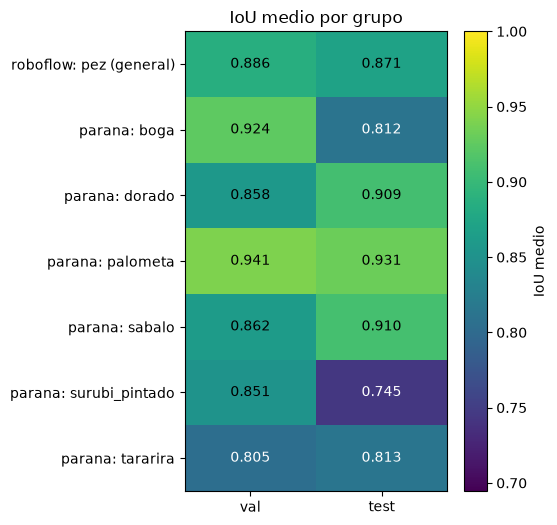

In [5]:
def group_label(r):
    if r.source == "roboflow":
        return "roboflow: pez (general)"
    return "parana: " + r["name"].split("__")[1]

stats["grupo"] = stats.apply(group_label, axis=1)

def summarize(g):
    return pd.Series(dict(n=len(g), IoU_medio=g.iou.mean(), IoU_mediana=g.iou.median(),
                          IoU_std=g.iou.std(), pct_IoU_menor_05=100 * (g.iou < 0.5).mean()))

# Tabla: filas = grupo, columnas = split (val/test) x métrica
tabla = stats.groupby(["grupo", "split"]).apply(summarize).unstack("split").round(3)
tabla = tabla.reindex(sorted(tabla.index, key=lambda x: (not x.startswith("roboflow"), x)))
display(tabla)
tabla.to_csv(RUNS / f"iou_por_grupo_{RUN_NAME}.csv")

# Matriz (heatmap) de IoU medio: grupo x split
mat = stats.pivot_table(index="grupo", columns="split", values="iou", aggfunc="mean")
mat = mat.reindex(tabla.index)[["val", "test"]]
fig, ax = plt.subplots(figsize=(5.5, 0.55 * len(mat) + 1.5))
im = ax.imshow(mat.values, cmap="viridis", vmin=max(0, np.nanmin(mat.values) - 0.05), vmax=1, aspect="auto")
ax.set_xticks(range(mat.shape[1]), mat.columns); ax.set_yticks(range(len(mat)), mat.index)
for i in range(mat.shape[0]):
    for j in range(mat.shape[1]):
        v = mat.values[i, j]
        ax.text(j, i, "-" if np.isnan(v) else f"{v:.3f}", ha="center", va="center", color="w" if v < 0.85 else "k")
fig.colorbar(im, ax=ax, label="IoU medio")
ax.set_ylabel(""); ax.set_xlabel("")
ax.set_title("IoU medio por grupo")
plt.tight_layout(); fig.savefig(RUNS / f"iou_matriz_{RUN_NAME}.png", dpi=110); plt.show()

### Curvas de entrenamiento

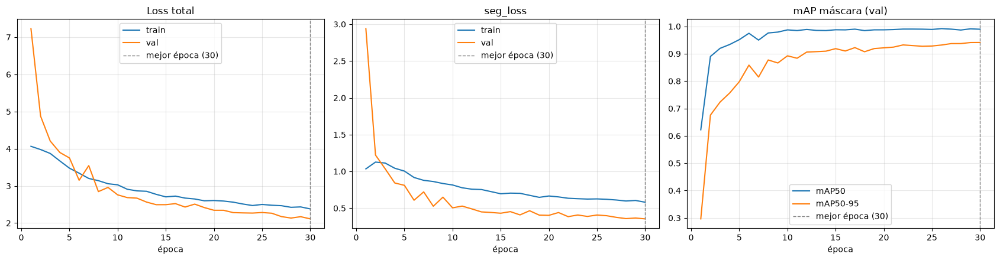

In [6]:
log = pd.read_csv(RUNS / RUN_NAME / "results.csv"); log.columns = log.columns.str.strip()
best_ep = int(log.loc[log["metrics/mAP50-95(M)"].idxmax(), "epoch"])
tr = [c for c in log.columns if c.startswith("train/") and c.endswith("_loss")]
va = [c for c in log.columns if c.startswith("val/") and c.endswith("_loss")]
ep = log["epoch"]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
axes[0].plot(ep, log[tr].sum(axis=1), label="train"); axes[0].plot(ep, log[va].sum(axis=1), label="val"); axes[0].set_title("Loss total")
axes[1].plot(ep, log["train/seg_loss"], label="train"); axes[1].plot(ep, log["val/seg_loss"], label="val"); axes[1].set_title("seg_loss")
axes[2].plot(ep, log["metrics/mAP50(M)"], label="mAP50"); axes[2].plot(ep, log["metrics/mAP50-95(M)"], label="mAP50-95"); axes[2].set_title("mAP máscara (val)")
for ax in axes:
    ax.axvline(best_ep, color="gray", ls="--", lw=1, label=f"mejor época ({best_ep})")
    ax.set_xlabel("época"); ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); fig.savefig(RUNS / f"curves_{RUN_NAME}.png", dpi=110); plt.show()

## 4. Ejemplos en test (mayor confianza, menor confianza y peores casos)

Verde = máscara real. Se muestran 8 de cada fuente en cada grilla.

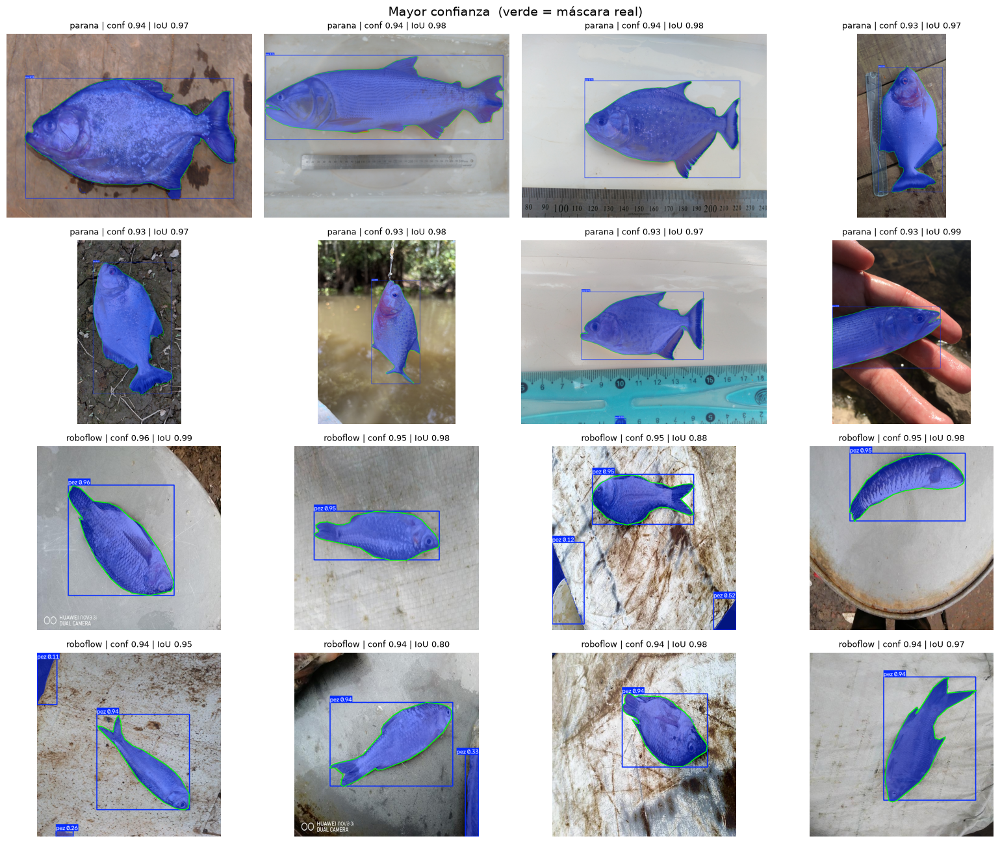

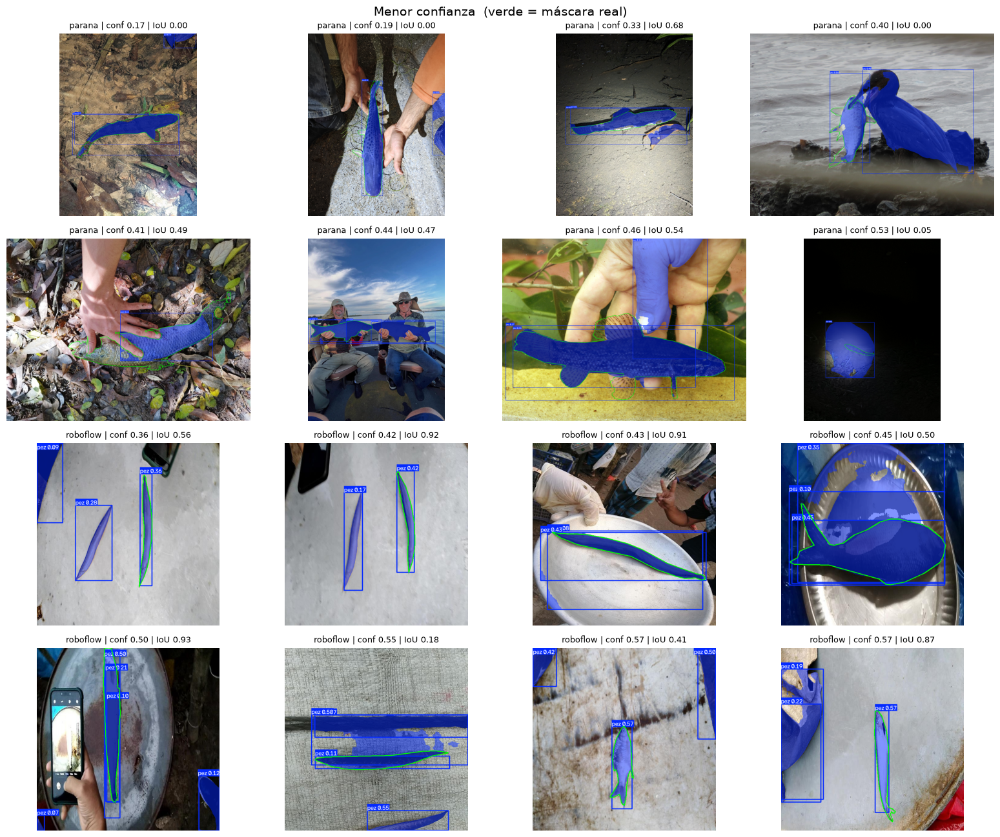

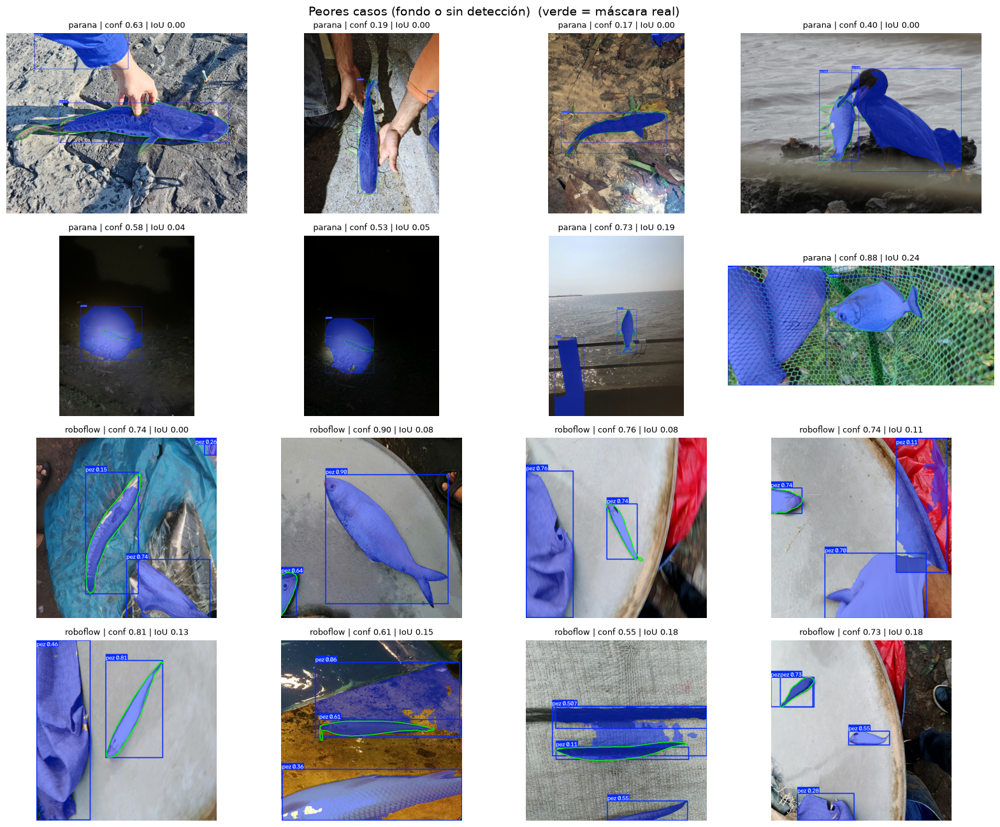

In [7]:
def plot_examples(sel, title, fname, split="test"):
    n = len(sel)
    cols = 4; rows_ = max(1, int(np.ceil(n / cols)))
    fig, axes = plt.subplots(rows_, cols, figsize=(16, 3.3 * rows_))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes: ax.axis("off")
    for ax, (_, s) in zip(axes, sel.iterrows()):
        res = predict(OUT / "images" / split / s["name"], conf=0.05)
        im = res.plot(line_width=2, font_size=10)
        h, w = im.shape[:2]
        for l in (OUT / "labels" / split / (Path(s["name"]).stem + ".txt")).read_text().splitlines():
            v = l.split()
            xy = (np.array(v[1:], float).reshape(-1, 2) * [w, h]).round().astype(np.int32)
            cv2.polylines(im, [xy], True, (0, 255, 0), 2)
        ax.imshow(im[..., ::-1])
        ax.set_title(f"{s['source']} | conf {s['max_conf']:.2f} | IoU {s['iou']:.2f}", fontsize=9)
    fig.suptitle(title + "  (verde = máscara real)", fontsize=14)
    plt.tight_layout(); fig.savefig(RUNS / fname, dpi=110); plt.show()

te = stats[stats.split == "test"]
def per_source(frame, k=8):
    return pd.concat([g.head(k) for _, g in frame.groupby("source")])

plot_examples(per_source(te.sort_values("max_conf", ascending=False)), "Mayor confianza", f"examples_{RUN_NAME}_high_conf.png")
plot_examples(per_source(te[te.max_conf > 0].sort_values("max_conf")), "Menor confianza", f"examples_{RUN_NAME}_low_conf.png")
plot_examples(per_source(te.assign(_none=te.pred_area == 0).sort_values(["iou", "_none", "max_conf"], ascending=[True, True, False])),
              "Peores casos (fondo o sin detección)", f"examples_{RUN_NAME}_failures.png")

### Imágenes del Paraná con menor IoU (val + test)

Cambiar `NRO_IMAGENES`; la figura se ajusta sola. Verde = máscara real.

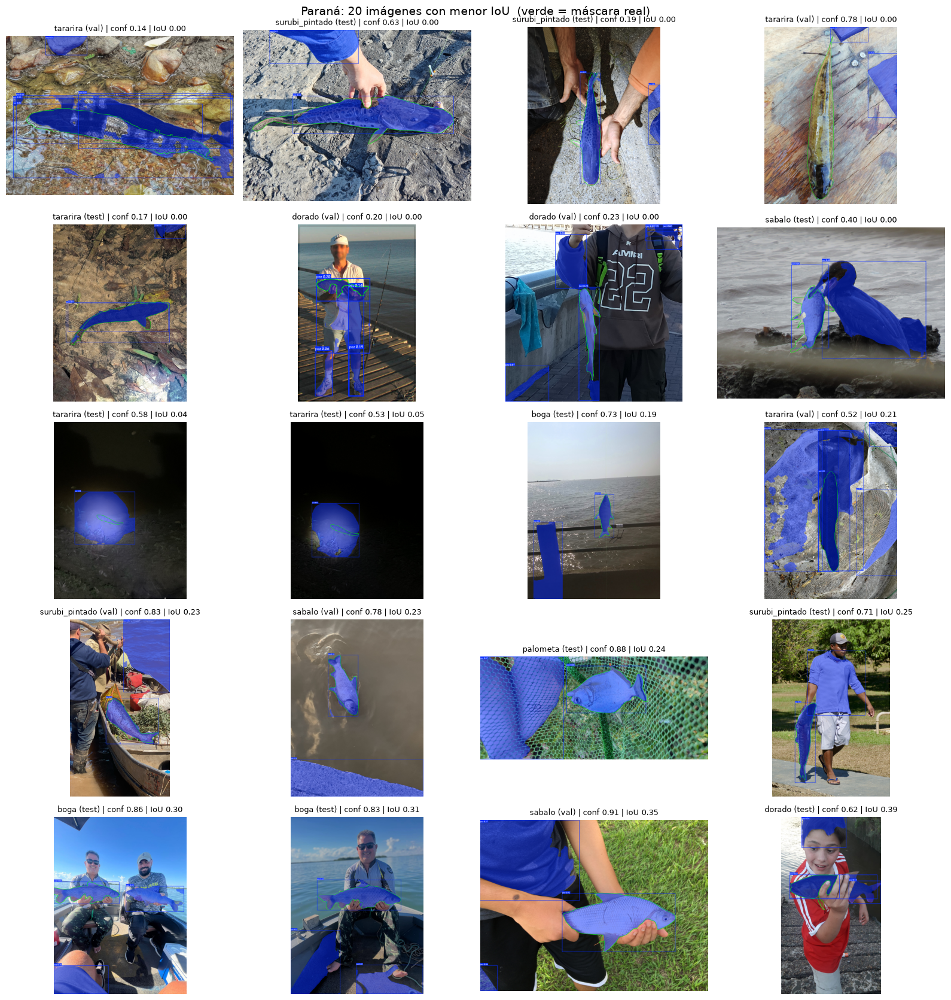

In [8]:
NRO_IMAGENES = 20
COLS = 4

worst = stats[stats.source == "parana"].sort_values("iou").head(NRO_IMAGENES)
n = len(worst)
rows_ = max(1, int(np.ceil(n / COLS)))
fig, axes = plt.subplots(rows_, COLS, figsize=(4 * COLS, 3.4 * rows_))
axes = np.atleast_1d(axes).ravel()
for ax in axes: ax.axis("off")
for ax, (_, s) in zip(axes, worst.iterrows()):
    res = predict(OUT / "images" / s["split"] / s["name"], conf=0.05)
    im = res.plot(line_width=2, font_size=10)
    h, w = im.shape[:2]
    for l in (OUT / "labels" / s["split"] / (Path(s["name"]).stem + ".txt")).read_text().splitlines():
        v = l.split()
        xy = (np.array(v[1:], float).reshape(-1, 2) * [w, h]).round().astype(np.int32)
        cv2.polylines(im, [xy], True, (0, 255, 0), 2)
    ax.imshow(im[..., ::-1])
    ax.set_title(f"{s['name'].split('__')[1]} ({s['split']}) | conf {s['max_conf']:.2f} | IoU {s['iou']:.2f}", fontsize=9)
fig.suptitle(f"Paraná: {n} imágenes con menor IoU  (verde = máscara real)", fontsize=14)
plt.tight_layout(); fig.savefig(RUNS / f"worst_parana_{RUN_NAME}.png", dpi=110); plt.show()

## 5. Exportar

Pesos finales en `runs/yolov8n-seg_merged/weights/best.pt`. Opcional: exportar a ONNX.

In [9]:
print("Pesos:", RUNS / RUN_NAME / "weights" / "best.pt")
# best.export(format="onnx", imgsz=HYP["imgsz"])   # descomentar si se necesita

Pesos: C:\Users\juanm\Documents\GitHub\fish_cv_pfc\runs\yolov8n-seg_merged\weights\best.pt
